Loaded: (367, 367, 3) (373, 373, 3)


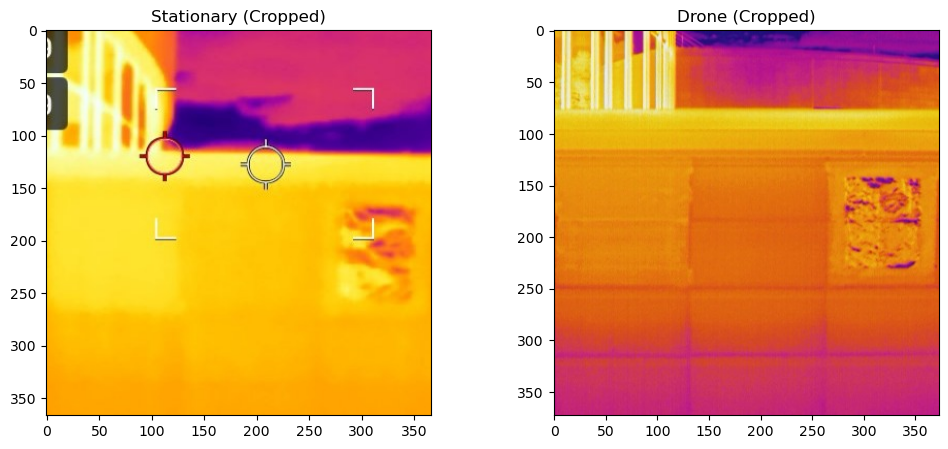

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import seaborn as sns

# ----------------------------
# UPDATE THESE PATHS
# ----------------------------
stat_path = r"C:\Users\murat\Downloads\STAT CROPPED NOV 17.JPG"
drone_path = r"C:\Users\murat\Downloads\DRONE CROPPED NOV 17.JPG"

# Load images (RGB for plotting, grayscale for pixel math)
stat_rgb = cv2.cvtColor(cv2.imread(stat_path), cv2.COLOR_BGR2RGB)
drone_rgb = cv2.cvtColor(cv2.imread(drone_path), cv2.COLOR_BGR2RGB)

stat_gray = cv2.cvtColor(stat_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
drone_gray = cv2.cvtColor(drone_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)

print("Loaded:", stat_rgb.shape, drone_rgb.shape)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1); plt.imshow(stat_rgb); plt.title("Stationary (Cropped)")
plt.subplot(1,2,2); plt.imshow(drone_rgb); plt.title("Drone (Cropped)")
plt.show()


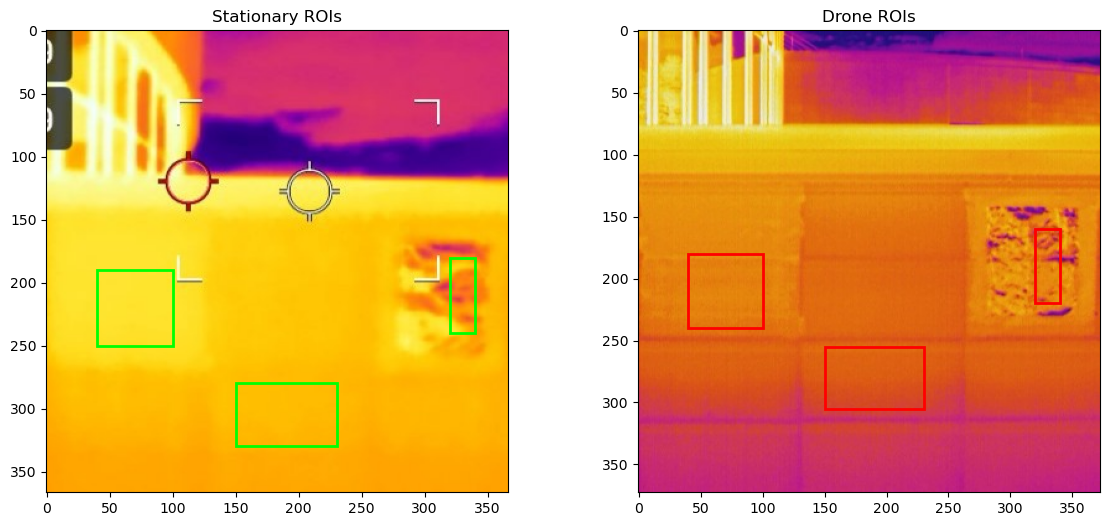

In [3]:
# =============================================
# MANUAL ROIs (x1, y1, x2, y2)
# ADJUST  BY LOOKING AT THE IMAGES
# =============================================

ROI_STAT = [
    (320, 180, 340, 240),   # Foil
    (40, 190, 100, 250),    # Black tape
    (150, 280, 230, 330)    # Background wall
]

ROI_DRONE = [
    (320, 160, 340, 220),   # Foil (match)
    (40, 180, 100, 240),    # Black tape (match)
    (150, 255, 230, 305)    # Background wall (match)
]

# Visualize
fig, ax = plt.subplots(1,2, figsize=(14,6))
ax[0].imshow(stat_rgb); ax[0].set_title("Stationary ROIs")
for (x1,y1,x2,y2) in ROI_STAT:
    ax[0].add_patch(plt.Rectangle((x1,y1), x2-x1, y2-y1,
                                   edgecolor='lime', linewidth=2, fill=False))

ax[1].imshow(drone_rgb); ax[1].set_title("Drone ROIs")
for (x1,y1,x2,y2) in ROI_DRONE:
    ax[1].add_patch(plt.Rectangle((x1,y1), x2-x1, y2-y1,
                                   edgecolor='red', linewidth=2, fill=False))
plt.show()


In [16]:
# =============================================
# CELL 4 (ENHANCED): Extract MULTIPLE samples from ROIs
# Using percentiles and spatial sampling for robustness
# =============================================
stat_samples = []
drone_samples = []

# Extract multiple samples per ROI for better statistics
for i, (roi_s, roi_d) in enumerate(zip(ROI_STAT, ROI_DRONE)):
    x1_s, y1_s, x2_s, y2_s = roi_s
    x1_d, y1_d, x2_d, y2_d = roi_d
    
    stat_region = stat_gray[y1_s:y2_s, x1_s:x2_s].flatten()
    drone_region = drone_gray[y1_d:y2_d, x1_d:x2_d].flatten()
    
    # Method 1: Use mean ± std samples
    stat_mean = np.mean(stat_region)
    drone_mean = np.mean(drone_region)
    
    # Add the mean
    stat_samples.append(stat_mean)
    drone_samples.append(drone_mean)
    
    # Method 2: Add percentiles for more data points
    percentiles = [10, 25, 50, 75, 90]
    for p in percentiles:
        stat_samples.append(np.percentile(stat_region, p))
        drone_samples.append(np.percentile(drone_region, p))
    
    print(f"ROI {i+1}: Stat={stat_mean:.2f}±{np.std(stat_region):.2f}, "
          f"Drone={drone_mean:.2f}±{np.std(drone_region):.2f}, "
          f"Samples={len(stat_region)}")

stat_samples = np.array(stat_samples)
drone_samples = np.array(drone_samples)

print(f"\nTotal calibration points: {len(stat_samples)}")

ROI 1: Stat=163.59±21.47, Drone=135.76±18.33, Samples=1200
ROI 2: Stat=214.38±1.37, Drone=145.41±3.98, Samples=3600
ROI 3: Stat=185.50±2.21, Drone=120.52±6.78, Samples=4000

Total calibration points: 18


In [19]:
# =============================================
# CELL 4B (ALTERNATIVE): Dense sampling with filtering
# Use pixels within 1 std of mean for each ROI
# =============================================
stat_samples_dense = []
drone_samples_dense = []

for i, (roi_s, roi_d) in enumerate(zip(ROI_STAT, ROI_DRONE)):
    x1_s, y1_s, x2_s, y2_s = roi_s
    x1_d, y1_d, x2_d, y2_d = roi_d
    
    stat_region = stat_gray[y1_s:y2_s, x1_s:x2_s].flatten()
    drone_region = drone_gray[y1_d:y2_d, x1_d:x2_d].flatten()
    
    # Filter to pixels within 1.5 standard deviations of mean
    stat_mean, stat_std = np.mean(stat_region), np.std(stat_region)
    drone_mean, drone_std = np.mean(drone_region), np.std(drone_region)
    
    stat_mask = np.abs(stat_region - stat_mean) <= 1.5 * stat_std
    drone_mask = np.abs(drone_region - drone_mean) <= 1.5 * drone_std
    
    # Only keep matching indices where BOTH are within range
    valid_mask = stat_mask & drone_mask
    
    stat_filtered = stat_region[valid_mask]
    drone_filtered = drone_region[valid_mask]
    
    # Subsample if too many points (optional, for speed)
    max_samples_per_roi = 200
    if len(stat_filtered) > max_samples_per_roi:
        indices = np.random.choice(len(stat_filtered), max_samples_per_roi, replace=False)
        stat_filtered = stat_filtered[indices]
        drone_filtered = drone_filtered[indices]
    
    stat_samples_dense.extend(stat_filtered)
    drone_samples_dense.extend(drone_filtered)
    
    print(f"ROI {i+1}: {len(stat_filtered)} valid samples "
          f"(filtered from {len(stat_region)} total)")

stat_samples_dense = np.array(stat_samples_dense)
drone_samples_dense = np.array(drone_samples_dense)

print(f"\nTotal calibration points: {len(stat_samples_dense)}")

ROI 1: 200 valid samples (filtered from 1200 total)
ROI 2: 200 valid samples (filtered from 3600 total)
ROI 3: 200 valid samples (filtered from 4000 total)

Total calibration points: 600


In [20]:
# =============================================
# CELL 5 (ENHANCED): Build calibration with multiple methods
# =============================================
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge, HuberRegressor

# Choose your dataset (dense sampling recommended)
X_train = drone_samples_dense.reshape(-1, 1)
y_train = stat_samples_dense

# Method 1: Linear Regression (Original)
model_linear = LinearRegression()
model_linear.fit(X_train, y_train)
y_pred_linear = model_linear.predict(X_train)
r2_linear = r2_score(y_train, y_pred_linear)

# Method 2: Robust Regression (handles outliers better)
model_robust = HuberRegressor(epsilon=1.5)
model_robust.fit(X_train, y_train)
y_pred_robust = model_robust.predict(X_train)
r2_robust = r2_score(y_train, y_pred_robust)

# Method 3: Polynomial (degree 2)
poly_features = PolynomialFeatures(degree=2)
X_poly = poly_features.fit_transform(X_train)
model_poly = LinearRegression()
model_poly.fit(X_poly, y_train)
y_pred_poly = model_poly.predict(X_poly)
r2_poly = r2_score(y_train, y_pred_poly)

# Print comparison
print("="*60)
print("CALIBRATION MODEL COMPARISON")
print("="*60)
print(f"Linear:     y = {model_linear.coef_[0]:.4f}x + {model_linear.intercept_:.4f}")
print(f"            R² = {r2_linear:.4f}")
print(f"\nRobust:     y = {model_robust.coef_[0]:.4f}x + {model_robust.intercept_:.4f}")
print(f"            R² = {r2_robust:.4f}")
print(f"\nPolynomial: y = {model_poly.coef_[2]:.4f}x² + {model_poly.coef_[1]:.4f}x + {model_poly.intercept_:.4f}")
print(f"            R² = {r2_poly:.4f}")
print("="*60)

# Select best model
best_r2 = max(r2_linear, r2_robust, r2_poly)
if best_r2 == r2_linear:
    model = model_linear
    model_name = "Linear"
    slope, intercept = model.coef_[0], model.intercept_
elif best_r2 == r2_robust:
    model = model_robust
    model_name = "Robust"
    slope, intercept = model.coef_[0], model.intercept_
else:
    model = model_poly
    model_name = "Polynomial"
    
print(f"\n✓ Selected model: {model_name} (R² = {best_r2:.4f})")

CALIBRATION MODEL COMPARISON
Linear:     y = 0.2435x + 153.7160
            R² = 0.0179

Robust:     y = 0.3908x + 136.2528
            R² = -0.0002

Polynomial: y = -0.0395x² + 10.7953x + -544.1036
            R² = 0.0655

✓ Selected model: Polynomial (R² = 0.0655)


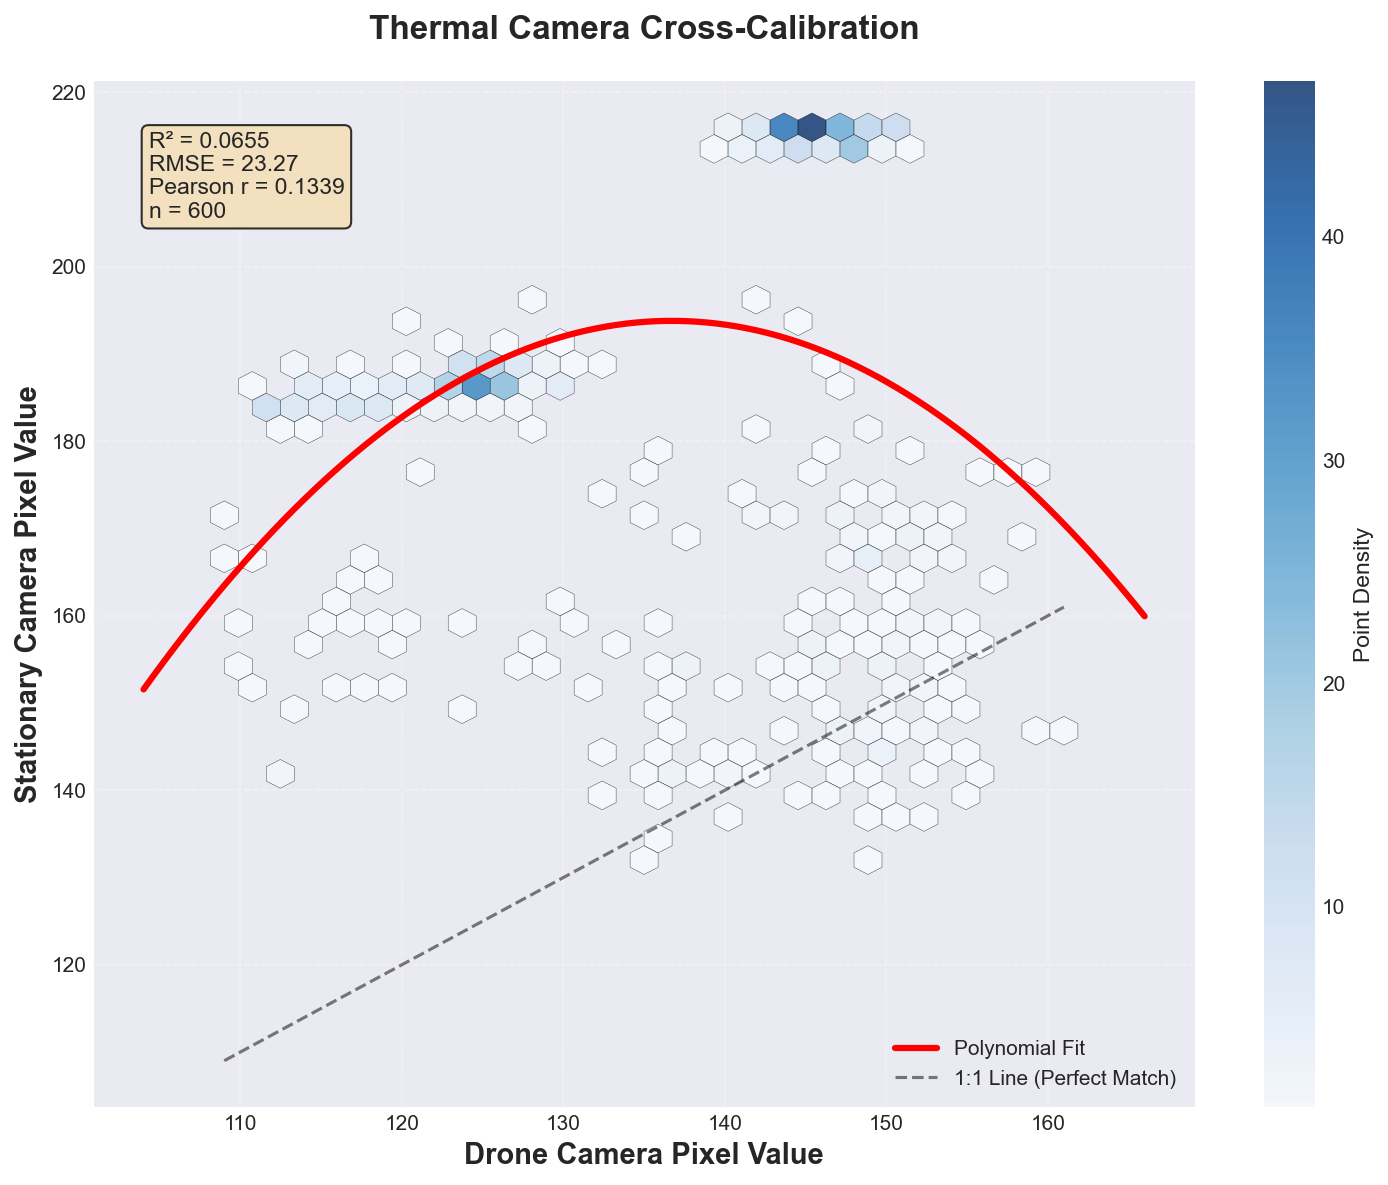


Model Performance:
  R² Score: 0.0655
  RMSE: 23.27 pixel values
  Pearson Correlation: 0.1339 (p < 1.01e-03)


In [21]:
# =============================================
# CELL 6 (PUBLICATION READY): Beautiful calibration plot
# =============================================
import matplotlib.pyplot as plt
from scipy import stats

plt.style.use('seaborn-v0_8-darkgrid')
fig, ax = plt.subplots(figsize=(10, 8), dpi=150)

# Scatter plot with density coloring
from matplotlib.colors import LinearSegmentedColormap
scatter = ax.hexbin(X_train.flatten(), y_train, gridsize=30, cmap='Blues', 
                    mincnt=1, alpha=0.8, edgecolors='black', linewidths=0.2)

# Plot calibration line
x_range = np.linspace(X_train.min() - 5, X_train.max() + 5, 200)
if model_name == "Polynomial":
    x_range_poly = poly_features.transform(x_range.reshape(-1, 1))
    y_range = model.predict(x_range_poly)
else:
    y_range = model.predict(x_range.reshape(-1, 1))

ax.plot(x_range, y_range, 'r-', linewidth=3, label=f'{model_name} Fit', zorder=10)

# Add confidence interval (for linear/robust only)
if model_name in ["Linear", "Robust"]:
    # Calculate prediction interval
    residuals = y_train - model.predict(X_train)
    std_error = np.std(residuals)
    margin = 1.96 * std_error  # 95% confidence
    
    ax.fill_between(x_range, y_range - margin, y_range + margin, 
                     color='red', alpha=0.2, label='95% Confidence Interval')

# Add 1:1 reference line
ax.plot([X_train.min(), X_train.max()], [X_train.min(), X_train.max()], 
        'k--', linewidth=1.5, alpha=0.5, label='1:1 Line (Perfect Match)')

# Calculate additional statistics
pearson_r, pearson_p = stats.pearsonr(X_train.flatten(), y_train)
rmse = np.sqrt(np.mean((y_train - model.predict(X_train if model_name != "Polynomial" else X_poly))**2))

# Add text box with statistics
textstr = f'R² = {best_r2:.4f}\n'
textstr += f'RMSE = {rmse:.2f}\n'
textstr += f'Pearson r = {pearson_r:.4f}\n'
textstr += f'n = {len(X_train)}'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Labels and title
ax.set_xlabel('Drone Camera Pixel Value', fontsize=14, fontweight='bold')
ax.set_ylabel('Stationary Camera Pixel Value', fontsize=14, fontweight='bold')
ax.set_title('Thermal Camera Cross-Calibration', fontsize=16, fontweight='bold', pad=20)

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Point Density', fontsize=11)

# Legend
ax.legend(loc='lower right', fontsize=10, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

print(f"\nModel Performance:")
print(f"  R² Score: {best_r2:.4f}")
print(f"  RMSE: {rmse:.2f} pixel values")
print(f"  Pearson Correlation: {pearson_r:.4f} (p < {pearson_p:.2e})")

In [22]:
# =============================================
# CELL 7: Apply Calibration to Full Drone Image
# =============================================
# Apply linear transformation to entire drone image
drone_calibrated = slope * drone_gray + intercept

# Clip to valid range (0-255 for grayscale)
drone_calibrated = np.clip(drone_calibrated, 0, 255).astype(np.uint8)

print("Calibrated Image Stats:")
print(f"  Min: {drone_calibrated.min()}, Max: {drone_calibrated.max()}")
print(f"  Mean: {drone_calibrated.mean():.2f}, Std: {drone_calibrated.std():.2f}")

Calibrated Image Stats:
  Min: 89, Max: 255
  Mean: 184.38, Std: 31.44


ValueError: operands could not be broadcast together with shapes (367,367) (373,373) 

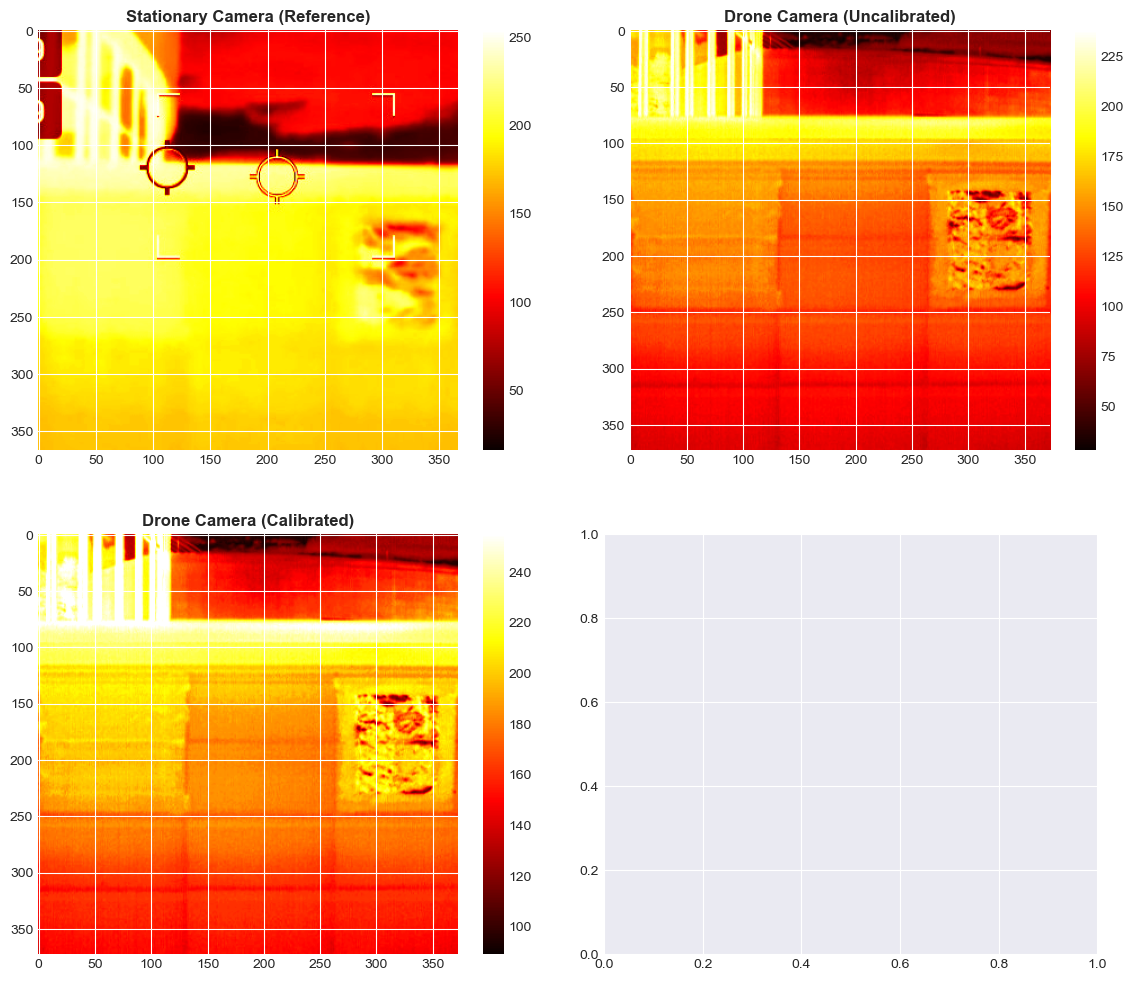

In [23]:
# =============================================
# CELL 8: Visual Comparison - Before & After
# =============================================
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Original stationary
im0 = axes[0, 0].imshow(stat_gray, cmap='hot')
axes[0, 0].set_title('Stationary Camera (Reference)', fontsize=12, fontweight='bold')
plt.colorbar(im0, ax=axes[0, 0], fraction=0.046)

# Original drone
im1 = axes[0, 1].imshow(drone_gray, cmap='hot')
axes[0, 1].set_title('Drone Camera (Uncalibrated)', fontsize=12, fontweight='bold')
plt.colorbar(im1, ax=axes[0, 1], fraction=0.046)

# Calibrated drone
im2 = axes[1, 0].imshow(drone_calibrated, cmap='hot')
axes[1, 0].set_title('Drone Camera (Calibrated)', fontsize=12, fontweight='bold')
plt.colorbar(im2, ax=axes[1, 0], fraction=0.046)

# Difference map
difference = np.abs(stat_gray.astype(np.float32) - drone_calibrated.astype(np.float32))
im3 = axes[1, 1].imshow(difference, cmap='coolwarm', vmin=0, vmax=50)
axes[1, 1].set_title('Absolute Difference (Stat - Calibrated Drone)', fontsize=12, fontweight='bold')
plt.colorbar(im3, ax=axes[1, 1], fraction=0.046, label='Pixel Difference')

for ax in axes.flat:
    ax.axis('off')

plt.tight_layout()
plt.show()

print(f"\nMean Absolute Difference: {difference.mean():.2f} pixel values")
print(f"Max Difference: {difference.max():.2f} pixel values")

In [24]:
# =============================================
# CELL 9: ROI Comparison Table
# =============================================
import pandas as pd

# Compare ROI values before and after calibration
roi_comparison = []
for i, (roi_s, roi_d) in enumerate(zip(ROI_STAT, ROI_DRONE)):
    x1_s, y1_s, x2_s, y2_s = roi_s
    x1_d, y1_d, x2_d, y2_d = roi_d
    
    stat_val = np.mean(stat_gray[y1_s:y2_s, x1_s:x2_s])
    drone_uncal = np.mean(drone_gray[y1_d:y2_d, x1_d:x2_d])
    drone_cal = np.mean(drone_calibrated[y1_d:y2_d, x1_d:x2_d])
    
    error_before = abs(stat_val - drone_uncal)
    error_after = abs(stat_val - drone_cal)
    improvement = ((error_before - error_after) / error_before) * 100
    
    roi_comparison.append({
        'ROI': f'ROI {i+1}',
        'Stationary': f'{stat_val:.2f}',
        'Drone (Before)': f'{drone_uncal:.2f}',
        'Drone (After)': f'{drone_cal:.2f}',
        'Error Before': f'{error_before:.2f}',
        'Error After': f'{error_after:.2f}',
        'Improvement': f'{improvement:.1f}%'
    })

df = pd.DataFrame(roi_comparison)
print("\n" + "="*80)
print("ROI COMPARISON TABLE")
print("="*80)
print(df.to_string(index=False))
print("="*80)


ROI COMPARISON TABLE
  ROI Stationary Drone (Before) Drone (After) Error Before Error After Improvement
ROI 1     163.59         135.76        189.00        27.83       25.41        8.7%
ROI 2     214.38         145.41        198.00        68.98       16.38       76.3%
ROI 3     185.50         120.52        174.92        64.98       10.58       83.7%
